Ejercicio 1

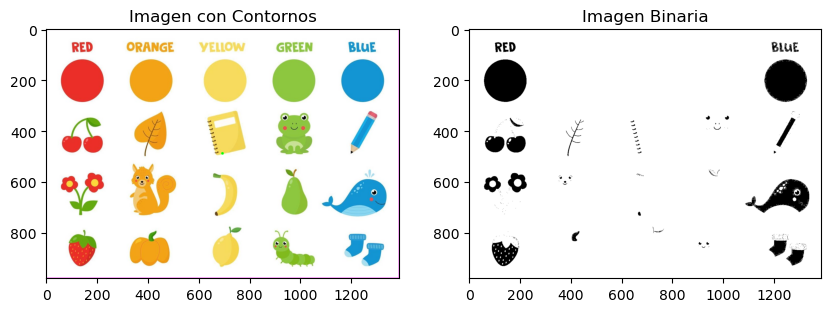

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Cargar la imagen
imagen = cv2.imread('../imagenes/colores2.jpg')
gray = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

# Umbralizar la imagen para obtener una imagen binaria
ret, bin = cv2.threshold(gray, 120, 250, cv2.THRESH_BINARY)  # Ajusta el valor de umbral según sea necesario

# Encontrar contornos en la imagen binaria
contorno, jeraquia = cv2.findContours(bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Listas para almacenar resultados
perimetros = []
areaa = []
vertices = []
centroides = []

for i in range(len(contorno)):
    cont = contorno[i]
    M = cv2.moments(cont)
    if M['m00'] != 0:
        cx = int(M['m10'] / M['m00'])
        cy = int(M['m01'] / M['m00'])
    else:
        cx, cy = 0, 0
    area = cv2.contourArea(cont)
    perimetro = cv2.arcLength(cont, True)
    epsilon = 0.02 * perimetro  
    vertice = cv2.approxPolyDP(cont, epsilon, True) 

    perimetros.append(perimetro)
    areaa.append(area)
    centroides.append(f'centroide: cx:{cx} , cy:{cy}')
    vertices.append(len(vertice))

    # Dibujar centroide
    cv2.circle(imagen, (cx, cy), 5, (0, 255, 0), -1)
    
    # Dibujar recuadro
    x, y, w, h = cv2.boundingRect(cont)
    cv2.rectangle(imagen, (x, y), (x + w, y + h), (255, 100, 255), 3)  # Recuadro

# Mostrar resultados
plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
plt.title('Imagen con Contornos')

plt.subplot(122)
plt.imshow(bin, cmap='gray')
plt.title('Imagen Binaria')

plt.show()


Ejercicio2

Text(0.5, 1.0, 'centroide,permitro')

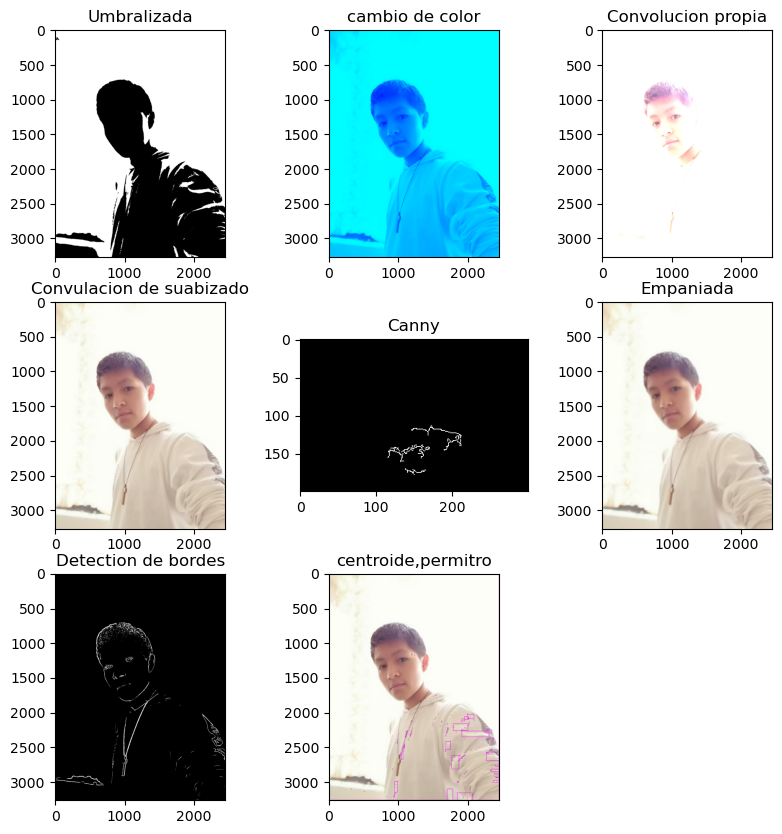

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

imagen = cv2.imread('../Examenes/segundo_examen/img3.jpg')
gray = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
ret, bin = cv2.threshold(gray, 250, 255, cv2.THRESH_BINARY ) #respuesta 1

escalar_imagen=cv2.normalize(gray,None,0,255,cv2.NORM_MINMAX)
apli_color=cv2.applyColorMap(escalar_imagen,cv2.COLORMAP_AUTUMN) #respuesta 2

mascara=np.array([[0,-1,-1],[-1,5,-1],[0,1,0]])
img_convolucion = cv2.filter2D(imagen,-1,mascara) #respuesta 3

kernerl5x5=np.ones((5,5),np.float32)/25 
suavizado=cv2.filter2D(imagen,-1,kernerl5x5)# respuesta 4

cortada=gray[1100:1300,900:1200]
canny = cv2.Canny(cortada, 40,200) #repuesta 5



imge_suavisada=cv2.GaussianBlur(imagen,(41,41),0)
mascara= np.ones_like(imagen,dtype=np.float32)
mascara*=3
mascara_suavisada=np.ones_like(imagen,dtype=np.float32)*0.7
empaniada= (imagen*0.3)+(imge_suavisada*0.7) #respuesta 6



img_gray=cv2.cvtColor(imagen,cv2.COLOR_BGR2GRAY)
img_gray=cv2.GaussianBlur(img_gray,(3,3),0)
sobelx=cv2.Sobel(img_gray,cv2.CV_64F,1,0,ksize=3)
sobely=cv2.Sobel(img_gray,cv2.CV_64F,0,1,ksize=3)
magnitud=np.sqrt(sobelx**2 + sobely**2)
magnitud=cv2.normalize(magnitud,None,0,255,cv2.NORM_MINMAX,cv2.CV_8U)
_,border=cv2.threshold(magnitud,30,255,cv2.THRESH_BINARY) 
kernel_morf=np.ones((2,2),np.uint8)
border=cv2.morphologyEx(border,cv2.MORPH_CLOSE,kernel_morf)# respuesta 7



ret,bin=cv2.threshold(gray,100,255,cv2.THRESH_OTSU)
contorno,jeraquia=cv2.findContours(bin,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
perimetros=[]
areaa=[]
for i in range(len(contorno)):
    cont=contorno[i]
    M=cv2.moments(cont)
    if M['m00']!=0:
        cx=int(M['m10']/M['m00'])
        cy=int(M['m01']/M['m00'])
    else:
        cx,cy=0,0
    area=cv2.contourArea(cont)
    perimetro=cv2.arcLength(cont,True) 
    
    perimetros.append(perimetros)
    areaa.append(area)

    cv2.circle(imagen,(cx,cy),5,(0,255,0),-1)
    x,y,w,h=cv2.boundingRect(cont)
    cv2.rectangle(imagen,(x,y),(x+w,y+h),(255,0,255),3)







plt.figure(figsize=(10,10))

plt.subplot(331)
plt.imshow(bin ,cmap='gray')
plt.title('Umbralizada')

plt.subplot(332)
plt.imshow(apli_color)
plt.title('cambio de color')

plt.subplot(333)
plt.imshow(cv2.cvtColor(img_convolucion,cv2.COLOR_BGR2RGB))
plt.title('Convolucion propia')

plt.subplot(334)
plt.imshow(cv2.cvtColor(suavizado,cv2.COLOR_BGR2RGB))
plt.title('Convulacion de suabizado')

plt.subplot(335)
plt.imshow(canny,cmap='gray')
plt.title('Canny')



plt.subplot(336)
plt.imshow(cv2.cvtColor(empaniada.astype(np.uint8),cv2.COLOR_BGR2RGB))
plt.title('Empaniada')

plt.subplot(337)
plt.imshow(border,cmap='gray')
plt.title('Detection de bordes')

plt.subplot(338)
plt.imshow(cv2.cvtColor(imagen,cv2.COLOR_BGR2RGB))
plt.title('centroide,permitro')





Ejercicio 3

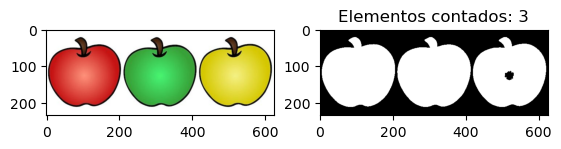

In [114]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import measure

def contar2(img):
    img_gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    _,binarizada=cv2.threshold(img_gray,223,255,cv2.THRESH_BINARY_INV)
    contorno=measure.label(binarizada,connectivity=2)
    cont=np.max(contorno)
    return cont,binarizada

imagen=cv2.imread('../imagenes/apples.jpg')
cont,bin=contar2(imagen)

plt.figure(figsize=(10,5))

plt.subplot(231)
plt.imshow(cv2.cvtColor(imagen,cv2.COLOR_BGR2RGB))

plt.subplot(232)
plt.title(f'Elementos contados: {cont}')
plt.imshow(bin,cmap='gray')
plt.show()


Ejercicio 4

La imagen tiene 180 bordes, lo cual significa que la habitacion esta limpia


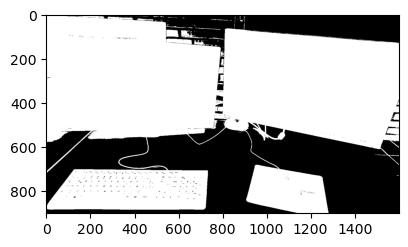

In [93]:
import matplotlib.pyplot as plt
from skimage import io, measure, color,filters
import numpy as np
import cv2

# image = io.imread('../imagenes/Habitacion1.jpg')
image = io.imread('../imagenes/escritorio2.jpg')

# gray_image = color.rgb2gray(image)
gray_image= cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
# edges = filters.sobel(gray_image)
_,binarizada=cv2.threshold(gray_image,127,255,cv2.THRESH_BINARY_INV)
labels = measure.label(binarizada ,connectivity=2)
borders = np.max(labels)

# border_muestra = 1165
border_muestra = 180

if borders >= border_muestra-5 and borders <= border_muestra+5 :
    print(f"La imagen tiene {borders} bordes, lo cual significa que la habitacion esta limpia")
else:
    print(f"La imagen tiene {borders} bordes, lo cual significa que la habitacion esta desordenada")


plt.figure(figsize=(10,10))
plt.subplot(121)
plt.imshow(binarizada,cmap='gray')
